# Chapitre 1 - Cours 4 : distribué ou mono-nœud

Troisième compromis du chapitre : quand faut-il répartir un système sur plusieurs
machines, et quand vaut-il mieux tout garder sur une seule ? Les systèmes distribués
apportent la tolérance aux pannes, l'échelle et la proximité géographique, mais ils ont un
coût : pannes partielles, latence du réseau, difficulté du diagnostic. Ce notebook couvre
la section *Distributed Versus Single-Node Systems* : *Problems with Distributed Systems*,
*Microservices and Serverless* et *Cloud Computing Versus Supercomputing*.

**Plan.**

1. Pourquoi distribuer : neuf raisons, dont la vitesse de la lumière et l'électricité
   verte.
2. Les problèmes du distribué : délais d'attente ambigus, réessais dangereux, coût d'un
   appel réseau, observabilité.
3. Quand un seul nœud suffit : la métrique COST et le coût du transfert des données.
4. Microservices et serverless : découper par équipes, payer à l'exécution.
5. Cloud contre supercalculateur : disponibilité contre points de reprise.

In [1]:
import json
import socket
import threading
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import architecture as ar
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.sim import Network, Node
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
rng = np.random.default_rng(0)
fmt = lambda v: f"{v:,.0f}".replace(",", " ")

## 1. Pourquoi distribuer ? (section *Distributed Versus Single-Node Systems*)

Un **système distribué** fait collaborer plusieurs machines qui communiquent par le
réseau ; chaque processus participant est un **nœud**. Le livre énumère les raisons d'en
construire un :

| raison | idée | renvoi |
|---|---|---|
| distribution inhérente | plusieurs utilisateurs sur leurs propres appareils doivent communiquer | |
| requêtes entre services cloud | données stockées dans un service, traitées dans un autre | cours 3 |
| tolérance aux pannes | si une machine (ou un centre de données) tombe, une autre prend le relais | chap. 2, 6 |
| scalabilité | données ou calculs trop gros pour une machine | chap. 2 |
| latence | servir chaque utilisateur depuis un serveur proche | ci-dessous |
| élasticité | ajuster les ressources à la demande | cours 3 |
| matériel spécialisé | disques pour le stockage, GPU pour l'apprentissage | cours 3 |
| conformité légale | lois de résidence des données dans certains pays | cours 5 |
| durabilité | calculer quand et où l'électricité est abondante et décarbonée | ci-dessous |

**La latence et la vitesse de la lumière.** Dans la fibre, la lumière parcourt environ
200 000 km/s, et les câbles ne suivent pas la ligne droite (on compte ici 1,5 fois la
distance orthodromique, `ar.fiber_rtt_ms`). Le temps d'aller-retour (RTT) minimal entre
deux villes est donc incompressible, quels que soient les serveurs.

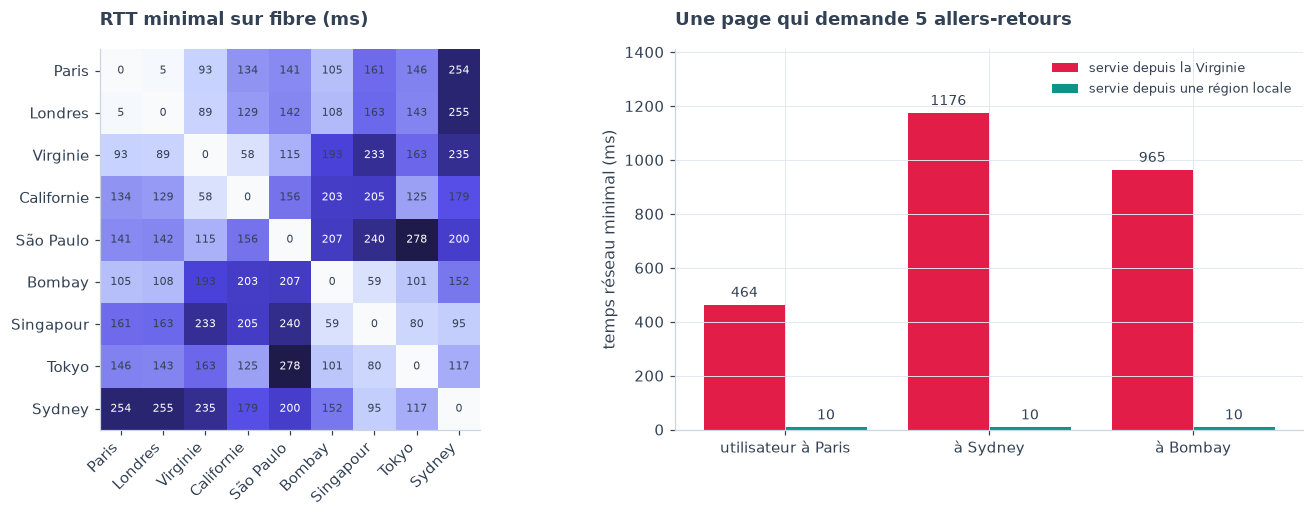

In [2]:
names = ["Paris", "Londres", "Virginie", "Californie", "São Paulo", "Bombay", "Singapour", "Tokyo", "Sydney"]
rtt = np.array([[ar.fiber_rtt_ms(ar.haversine_km(*ar.CITIES[a], *ar.CITIES[b])) for b in names] for a in names])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.15, 1]})
ax = axes[0]
im = ax.imshow(rtt, cmap="ddia_seq")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticks(range(len(names))); ax.set_yticklabels(names); ax.grid(False)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{rtt[i, j]:.0f}", ha="center", va="center", fontsize=7.5,
                color="white" if rtt[i, j] > 200 else SLATE)
ax.set_title("RTT minimal sur fibre (ms)")
ax = axes[1]
# une page sécurisée : connexion TCP (1 RTT) + TLS (1 RTT) + requête (1 RTT) + 2 appels API séquentiels
n_rtt = 5
srv = {"servie depuis la Virginie": [rtt[names.index(u), names.index("Virginie")] * n_rtt for u in ["Paris", "Sydney", "Bombay"]],
       "servie depuis la région la plus proche": [rtt[names.index(u), names.index(u)] * n_rtt + 5 * 2 for u in ["Paris", "Sydney", "Bombay"]]}
x = np.arange(3)
b1 = ax.bar(x - 0.2, srv["servie depuis la Virginie"], 0.4, color=ROSE, label="servie depuis la Virginie")
b2 = ax.bar(x + 0.2, srv["servie depuis la région la plus proche"], 0.4, color=TEAL, label="servie depuis une région locale")
annotate_bars(ax, "{:.0f}")
ax.set_xticks(x); ax.set_xticklabels(["utilisateur à Paris", "à Sydney", "à Bombay"])
ax.set_ylabel("temps réseau minimal (ms)"); ax.set_ylim(0, max(srv["servie depuis la Virginie"]) * 1.2)
ax.set_title(f"Une page qui demande {n_rtt} allers-retours"); ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

Un utilisateur à Sydney servi depuis la Virginie attend plus d'une seconde de pur trajet
réseau pour une page qui demande cinq allers-retours, avant tout calcul ; servi depuis
une région proche (on compte 2 ms par aller-retour local), une dizaine de millisecondes. Aucune optimisation logicielle ne
compense la physique : seule la **distribution géographique** des serveurs le peut, avec
les problèmes de réplication qu'elle entraîne (chapitre 6).

**La durabilité.** Une tâche différable (un traitement par lots, un entraînement) peut être
déplacée vers les heures et les lieux où l'électricité est abondante et décarbonée.
Exemple synthétique : l'intensité carbone d'un réseau électrique baisse en milieu de
journée grâce au solaire ; une tâche de 4 heures, à finir dans les 24 heures, peut
choisir sa fenêtre.

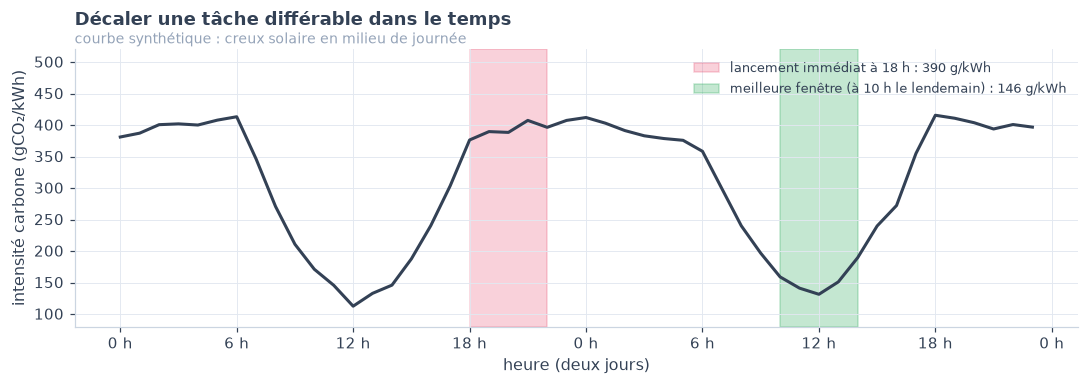

émissions réduites de 63% sans rien changer au calcul


In [3]:
hours = np.arange(48)
solar = np.clip(np.sin((hours % 24 - 6) / 12 * np.pi), 0, None)
carbon = 380 - 230 * solar + 25 * np.sin(hours / 3.0) + rng.normal(0, 8, hours.size)   # gCO2/kWh
job = 4
window = np.array([carbon[s:s + job].mean() for s in range(18, 18 + 24 - job + 1)])
best = 18 + int(window.argmin())
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(hours, carbon, color=SLATE)
ax.axvspan(18, 18 + job, color=ROSE, alpha=0.2, label=f"lancement immédiat à 18 h : {carbon[18:18 + job].mean():.0f} g/kWh")
ax.axvspan(best, best + job, color=GREEN, alpha=0.25, label=f"meilleure fenêtre (à {best % 24} h le lendemain) : {window.min():.0f} g/kWh")
ax.set_xticks(range(0, 49, 6)); ax.set_xticklabels([f"{h % 24} h" for h in range(0, 49, 6)])
ax.set_xlabel("heure (deux jours)"); ax.set_ylabel("intensité carbone (gCO₂/kWh)")
ax.set_title("Décaler une tâche différable dans le temps")
subtitle(ax, "courbe synthétique : creux solaire en milieu de journée")
ax.legend(fontsize=8.5, loc="upper right"); ax.set_ylim(80, 520)
plt.tight_layout(); plt.show()
print(f"émissions réduites de {1 - window.min() / carbon[18:18 + job].mean():.0%} sans rien changer au calcul")

> **À retenir.** On distribue pour des raisons qu'aucune machine unique ne satisfait :
> plusieurs utilisateurs, tolérance aux pannes, échelle, proximité géographique (la
> lumière ne va pas plus vite), élasticité, matériel spécialisé, lois de résidence,
> électricité décarbonée.

## 2. Les problèmes du distribué (section *Problems with Distributed Systems*)

**Le délai d'attente ambigu.** Toute requête qui traverse le réseau peut échouer : le
réseau peut couper, le service être surchargé ou tomber en panne. Le client ne voit alors
qu'une chose : **pas de réponse** avant l'expiration de son délai d'attente (« timeout »).
Il ne sait pas si sa requête a été traitée. Les trois scénarios ci-dessous, très
différents pour le serveur, sont **indiscernables** pour le client.

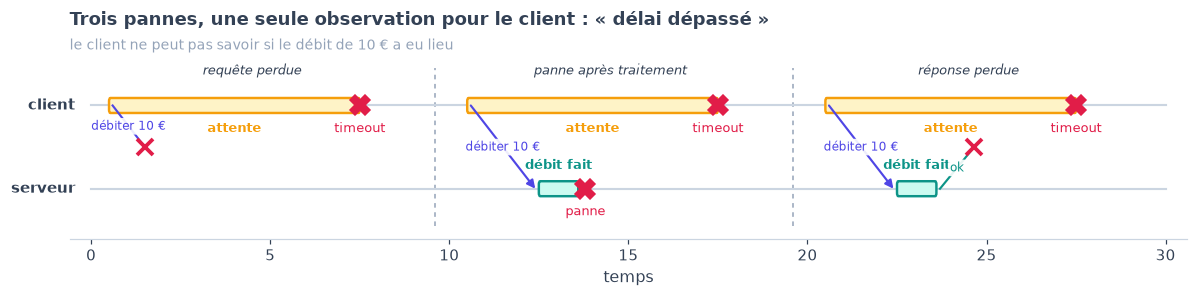

In [4]:
st = SpaceTime(["client", "serveur"], t_max=30, width=11,
               title="Trois pannes, une seule observation pour le client : « délai dépassé »",
               subtitle="le client ne peut pas savoir si le débit de 10 € a eu lieu")
for k, (title, lost_req, done, lost_resp) in enumerate([("requête perdue", True, False, False),
                                                        ("panne après traitement", False, True, True),
                                                        ("réponse perdue", False, True, True)]):
    t0 = k * 10
    st.vline(t0 + 9.6) if k < 2 else None
    st.note(t0 + 4.5, "client", title, dy=0.42, color=SLATE)
    st.op("client", t0 + 0.5, t0 + 7.5, "attente", color=AMBER, above=False)
    st.event("client", t0 + 7.5, "timeout", kind="crash", color=ROSE)
    st.msg("client", t0 + 0.6, "serveur", t0 + 2.4, "débiter 10 €", color=INDIGO, lost=lost_req)
    if done:
        st.op("serveur", t0 + 2.5, t0 + 3.6, "débit fait", color=TEAL)
    if k == 1:
        st.event("serveur", t0 + 3.8, "panne", kind="crash")
    if k == 2:
        st.msg("serveur", t0 + 3.7, "client", t0 + 5.6, "ok", color=TEAL, lost=True)
st.show()

**Réessayer n'est pas toujours sûr.** Le réflexe naturel est de renvoyer la requête. Dans
le premier scénario, c'est correct ; dans les deux autres, le compte est débité deux fois.
La parade est l'**idempotence** : le client joint à chaque requête une clé unique, et le
serveur ignore une clé déjà traitée (en renvoyant le résultat initial). Mesurons-le sur le
simulateur du dépôt (`ddia.sim`), avec 20 % de messages perdus et des réessais jusqu'au
succès.

In [5]:
class Bank(Node):
    def __init__(self, name, idempotent):
        super().__init__(name)
        self.idempotent, self.balance, self.seen = idempotent, 0, {}

    def on_message(self, src, msg):
        key, amount = msg
        if self.idempotent and key in self.seen:
            self.send(src, ("ok", key)); return
        self.balance -= amount
        self.seen[key] = True
        self.send(src, ("ok", key))


class Client(Node):
    def __init__(self, name, n_ops, timeout=6.0):
        super().__init__(name)
        self.n_ops, self.timeout, self.acked, self.sent = n_ops, timeout, set(), 0

    def on_start(self):
        for i in range(self.n_ops):
            self.set_timer(i * 20.0, self.attempt, i)

    def attempt(self, i):
        if i in self.acked:
            return
        self.sent += 1
        self.send("banque", (f"op-{i}", 10))
        self.set_timer(self.timeout, self.attempt, i)            # réessai si pas de réponse

    def on_message(self, src, msg):
        self.acked.add(int(msg[1].split("-")[1]))


rows = []
for idem in (False, True):
    net = Network(seed=7, latency=(0.5, 2.5), drop=0.2)
    bank, cli = net.add(Bank("banque", idem)), net.add(Client("client", 1000))
    net.run()
    rows.append({"serveur": "idempotent (clé unique)" if idem else "naïf",
                 "débits demandés": 1000, "requêtes envoyées": cli.sent,
                 "débits effectués": -bank.balance // 10, "solde attendu (€)": -10_000, "solde réel (€)": bank.balance})
pd.DataFrame(rows).set_index("serveur")

,débits demandés,requêtes envoyées,débits effectués,solde attendu (€),solde réel (€)
serveur,,,,,
naïf,1000,1559,1236,-10000,-12360
idempotent (clé unique),1000,1559,1000,-10000,-10000


Avec 20 % de pertes dans chaque sens, environ 36 % des tentatives échouent du point de vue
du client, et une part notable de ces échecs sont des réponses perdues : le serveur naïf
débite plusieurs fois. Avec une clé d'idempotence, le résultat est exact malgré les mêmes
réessais. Ces questions (délais, réessais, sémantique « exactement une fois ») sont au cœur
des chapitres 9 et 12.

**Un appel réseau coûte des ordres de grandeur.** Même dans un centre de données rapide,
appeler un autre service est **beaucoup** plus lent qu'appeler une fonction du même
processus. Mesurons sur cette machine un appel de fonction Python et un aller-retour TCP
sur l'interface locale (« localhost », donc sans même toucher un vrai réseau).

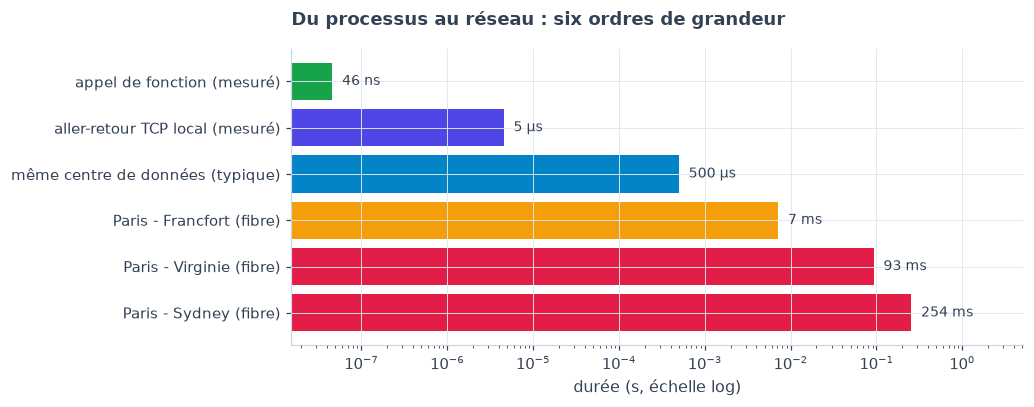

un aller-retour TCP local coûte environ 99 appels de fonction


In [6]:
def echo_server(sock):
    conn, _ = sock.accept()
    conn.setsockopt(socket.IPPROTO_TCP, socket.TCP_NODELAY, 1)
    while True:
        data = conn.recv(64)
        if not data:
            break
        conn.sendall(data)
    conn.close()


srv_sock = socket.socket(); srv_sock.bind(("127.0.0.1", 0)); srv_sock.listen(1)
th = threading.Thread(target=echo_server, args=(srv_sock,), daemon=True); th.start()
cli_sock = socket.create_connection(srv_sock.getsockname())
cli_sock.setsockopt(socket.IPPROTO_TCP, socket.TCP_NODELAY, 1)

def f(x):
    return x + 1

N_CALLS = 2000
t0 = time.perf_counter()
for i in range(N_CALLS):
    f(i)
t_func = (time.perf_counter() - t0) / N_CALLS
lat = []
for i in range(N_CALLS):
    t0 = time.perf_counter(); cli_sock.sendall(b"ping"); cli_sock.recv(64); lat.append(time.perf_counter() - t0)
cli_sock.close(); srv_sock.close()
t_local_rtt = float(np.median(lat))

levels = pd.Series({"appel de fonction (mesuré)": t_func,
                    "aller-retour TCP local (mesuré)": t_local_rtt,
                    "même centre de données (typique)": 500e-6,
                    "Paris - Francfort (fibre)": ar.fiber_rtt_ms(ar.haversine_km(*ar.CITIES["Paris"], *ar.CITIES["Francfort"])) / 1e3,
                    "Paris - Virginie (fibre)": ar.fiber_rtt_ms(ar.haversine_km(*ar.CITIES["Paris"], *ar.CITIES["Virginie"])) / 1e3,
                    "Paris - Sydney (fibre)": ar.fiber_rtt_ms(ar.haversine_km(*ar.CITIES["Paris"], *ar.CITIES["Sydney"])) / 1e3})
fig, ax = plt.subplots(figsize=(9.5, 3.8))
b = ax.barh(levels.index[::-1], levels.values[::-1], color=[ROSE, ROSE, AMBER, SKY, INDIGO, GREEN])
ax.set_xscale("log")
for bar, v in zip(b, levels.values[::-1]):
    lab = f"{v * 1e9:.0f} ns" if v < 1e-6 else (f"{v * 1e6:.0f} µs" if v < 1e-3 else f"{v * 1e3:.0f} ms")
    ax.text(v * 1.3, bar.get_y() + bar.get_height() / 2, lab, va="center", fontsize=9)
ax.set_xlim(levels.min() / 3, levels.max() * 20)
ax.set_xlabel("durée (s, échelle log)")
ax.set_title("Du processus au réseau : six ordres de grandeur")
plt.tight_layout(); plt.show()
print(f"un aller-retour TCP local coûte environ {t_local_rtt / t_func:,.0f} appels de fonction".replace(",", " "))

Un simple aller-retour sur l'interface locale coûte déjà de l'ordre d'une centaine
d'appels de fonction (le rapport exact dépend de la machine) ; un appel vers un autre
continent, des centaines de milliers. Un programme qui fait
en boucle des appels réseau là où il ferait des appels de fonction est donc
**structurellement** plus lent, quelle que soit la puissance des machines.

**L'observabilité.** Quand un système distribué est lent, où est le problème ? Les outils
de **traçage** distribué (OpenTelemetry, Zipkin, Jaeger) enregistrent, pour chaque requête,
quel service a appelé quel autre, pour quelle opération, et combien de temps chaque appel a
duré (des « spans »). Le livre parle d'**observabilité** : collecter des données
d'exécution qu'on peut interroger aussi bien en agrégats qu'au niveau d'un événement
individuel. Voici la trace d'une requête de page produit, et son **chemin critique**
(`ar.critical_path`) : la suite d'appels qui détermine réellement la durée totale.

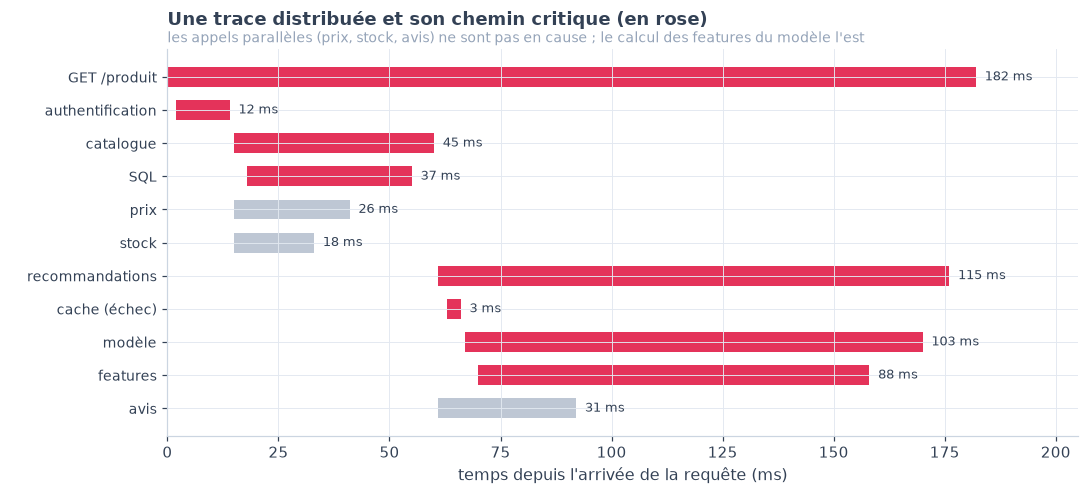

In [7]:
spans = {
    "GET /produit": (None, 0, 182),
    "authentification": ("GET /produit", 2, 14),
    "catalogue": ("GET /produit", 15, 60),
    "catalogue: SQL": ("catalogue", 18, 55),
    "prix": ("GET /produit", 15, 41),
    "stock": ("GET /produit", 15, 33),
    "recommandations": ("GET /produit", 61, 176),
    "reco: cache (échec)": ("recommandations", 63, 66),
    "reco: modèle": ("recommandations", 67, 170),
    "reco: modèle: features": ("reco: modèle", 70, 158),
    "avis": ("GET /produit", 61, 92),
}
crit = set(ar.critical_path(spans, "GET /produit"))
order = list(spans)
def depth(name):
    p, k = spans[name][0], 0
    while p is not None:
        k, p = k + 1, spans[p][0]
    return k


fig, ax = plt.subplots(figsize=(10, 4.6))
for i, name in enumerate(order):
    parent, t0, t1 = spans[name]
    ax.barh(i, t1 - t0, left=t0, color=ROSE if name in crit else GRAY, alpha=0.9 if name in crit else 0.6, height=0.6)
    ax.text(t1 + 2, i, f"{t1 - t0} ms", va="center", fontsize=8.5, color=SLATE)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(["    " * depth(n) + n.split(": ")[-1] for n in order], fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, 205)
ax.set_xlabel("temps depuis l'arrivée de la requête (ms)")
ax.set_title("Une trace distribuée et son chemin critique (en rose)")
subtitle(ax, "les appels parallèles (prix, stock, avis) ne sont pas en cause ; le calcul des features du modèle l'est")
plt.tight_layout(); plt.show()

Lire la trace évite les fausses pistes : le stock et les prix, appelés en parallèle du
catalogue, n'allongent rien ; la requête SQL du catalogue et surtout le calcul des
caractéristiques du modèle de recommandation (88 ms sur 182) sont sur le chemin critique.
C'est là, et seulement là, qu'une optimisation réduira le temps de réponse.

**La cohérence entre services.** Enfin, quand chaque service a sa propre base, garantir la
cohérence des données **entre** services devient le problème de l'application. Les
transactions distribuées (chapitre 8) existent, mais sont rarement
employées entre microservices : elles recouplent des services qu'on voulait indépendants,
et beaucoup de bases ne les proposent pas.

> **À retenir.** Dans un système distribué, toute requête peut échouer sans qu'on sache si
> elle a été traitée : les réessais exigent l'idempotence. Un appel réseau coûte d'une
> centaine à des centaines de milliers d'appels de fonction. Diagnostiquer demande du traçage, et la
> cohérence entre services devient l'affaire de l'application.

## 3. Quand un seul nœud suffit (section *Problems with Distributed Systems*)

Le livre est clair : faire une tâche sur une seule machine est souvent **bien plus simple
et moins cher** qu'un système distribué. Les processeurs, la mémoire et les disques ont
grossi, accéléré et gagné en fiabilité ; avec des bases mono-nœud comme DuckDB, SQLite ou
KùzuDB, beaucoup de charges tiennent sur une machine.

**La métrique COST.** McSherry, Isard et Murray ont proposé une mesure sévère : la
« configuration qui surpasse un seul thread » (*Configuration that Outperforms a Single
Thread*). Un système distribué fait plus de travail total qu'un bon programme mono-thread
(sérialisation, coordination, code générique) : s'il fait $k$ fois plus de travail, il lui
faut au moins $k$ cœurs pour simplement égaler le programme simple, et davantage avec les
coûts de synchronisation. Modèle : $T(n) = k\,T_1/n + s \log_2 n$ (`ar.cluster_time`).

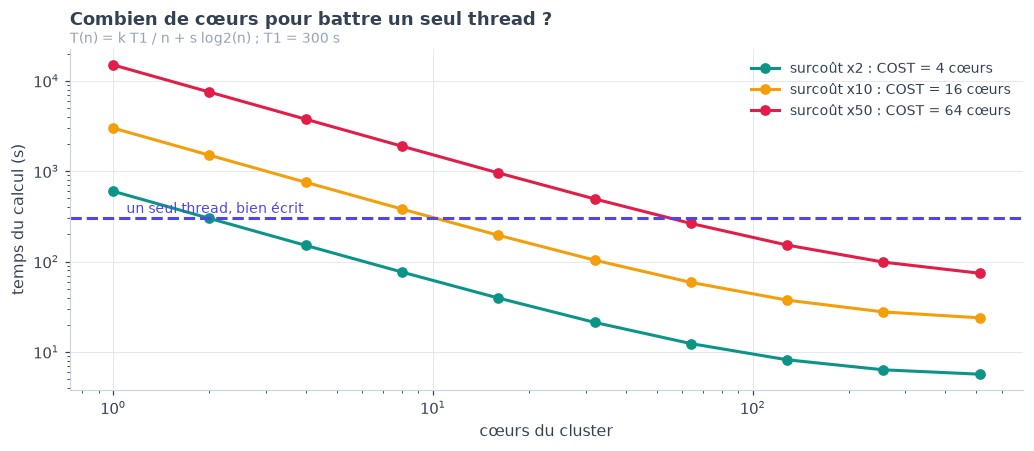

In [8]:
ns = np.array([1, 2, 4, 8, 16, 32, 64, 128, 256, 512])
T1 = 300.0                                    # secondes pour le programme mono-thread
fig, ax = plt.subplots(figsize=(9.5, 4.2))
for k, sync, c in [(2, 0.5, TEAL), (10, 2.0, AMBER), (50, 5.0, ROSE)]:
    t = ar.cluster_time(ns, T1, overhead=k, sync=sync)
    cst = ar.cost_metric(ns, t, T1)
    ax.loglog(ns, t, "o-", color=c, label=f"surcoût x{k} : COST = {cst if cst else '> 512'} cœurs")
ax.axhline(T1, color=INDIGO, lw=2, ls="--"); ax.text(1.1, T1 * 1.15, "un seul thread, bien écrit", color=INDIGO, fontsize=9)
ax.set_xlabel("cœurs du cluster"); ax.set_ylabel("temps du calcul (s)")
ax.set_title("Combien de cœurs pour battre un seul thread ?")
subtitle(ax, "T(n) = k T1 / n + s log2(n) ; T1 = 300 s")
ax.legend(fontsize=9); plt.tight_layout(); plt.show()

Avec un surcoût de 50 (plausible pour un framework générique qui sérialise chaque
enregistrement), il faut plus de 64 cœurs juste pour égaler un programme simple sur un
portable. L'article original rapportait des systèmes de traitement de graphes publiés
qui, sur des centaines de cœurs, battaient à peine (ou pas du tout) un seul thread.
D'où vient ce surcoût ? En bonne partie de la **sérialisation** : dès que les données
traversent le réseau, il faut les encoder. Comparons le calcul d'une somme sur un million
d'enregistrements et leur simple encodage en JSON (chapitre 5).

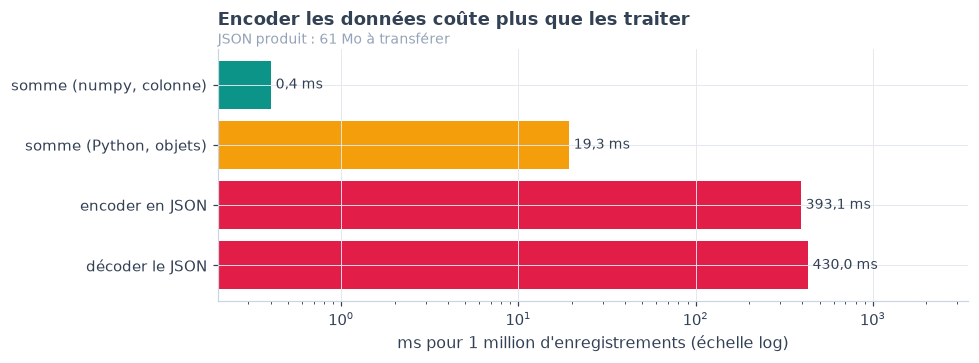

In [9]:
recs = [{"id": i, "magasin": int(s), "montant": float(a)} for i, (s, a) in
        enumerate(zip(rng.integers(0, 20, 1_000_000), rng.lognormal(3, 0.7, 1_000_000)))]
amounts = np.array([r["montant"] for r in recs])
t0 = time.perf_counter(); amounts.sum(); t_np = time.perf_counter() - t0
t0 = time.perf_counter(); sum(r["montant"] for r in recs); t_py = time.perf_counter() - t0
t0 = time.perf_counter(); blob = json.dumps(recs); t_ser = time.perf_counter() - t0
t0 = time.perf_counter(); json.loads(blob); t_de = time.perf_counter() - t0
cost = pd.Series({"somme (numpy, colonne)": t_np, "somme (Python, objets)": t_py,
                  "encoder en JSON": t_ser, "décoder le JSON": t_de}) * 1e3
fig, ax = plt.subplots(figsize=(9, 3.4))
b = ax.barh(cost.index[::-1], cost.values[::-1], color=[ROSE, ROSE, AMBER, TEAL])
ax.set_xscale("log"); ax.bar_label(b, labels=[f"{v:.1f} ms".replace(".", ",") for v in cost.values[::-1]], padding=3, fontsize=9)
ax.set_xlim(cost.min() / 2, cost.max() * 8)
ax.set_xlabel("ms pour 1 million d'enregistrements (échelle log)")
ax.set_title("Encoder les données coûte plus que les traiter")
subtitle(ax, f"JSON produit : {len(blob) / 1e6:.0f} Mo à transférer")
plt.tight_layout(); plt.show()

Encoder et décoder coûtent ici des dizaines à des centaines de fois le calcul utile, avant
même de payer le transfert de dizaines de mégaoctets. D'où un deuxième conseil du livre :
pour de gros volumes, il vaut souvent mieux **amener le calcul aux données** que l'inverse.

In [10]:
rows = []
for vol_tb in (0.1, 1, 10):
    b_ = vol_tb * 1e12
    rows.append({"volume": f"{vol_tb:g} To",
                 "transférer à 10 Gb/s (min)": b_ * 8 / 10e9 / 60,
                 "parcourir sur place à 2 Go/s (min)": b_ / 2e9 / 60,
                 "renvoyer un résultat de 0,1 % à 10 Gb/s (min)": b_ * 1e-3 * 8 / 10e9 / 60})
pd.DataFrame(rows).set_index("volume")

,transférer à 10 Gb/s (min),parcourir sur place à 2 Go/s (min),"renvoyer un résultat de 0,1 % à 10 Gb/s (min)"
volume,,,
0.1 To,1.333,0.833,0.001
1 To,13.333,8.333,0.013
10 To,133.333,83.333,0.133


Parcourir les données sur la machine qui les détient, puis renvoyer un petit résultat,
évite l'essentiel du transfert : 1,6 fois plus rapide que de déplacer les données même
avec un réseau à 10 Gb/s, et sans saturer ce réseau. La séparation stockage/calcul du
cours 3 a donc un prix, que les systèmes cloud native compensent par des caches et en
poussant des filtres vers le stockage.

> **À retenir.** Plus de nœuds ne veut pas dire plus rapide : un système distribué paie
> sérialisation, coordination et transferts. Avant de distribuer, vérifier qu'une seule
> (grosse) machine ne suffit pas ; et, à grande échelle, amener le calcul aux données.